Fitted parameters: mu = 2.9024445992261896, sigma = 0.4233772860073253, lambda = 0.07408804886392666, A = 0.38774637314333377
Log-normal median: 18.218628220368632
Log-normal mode: 15.228920322837427


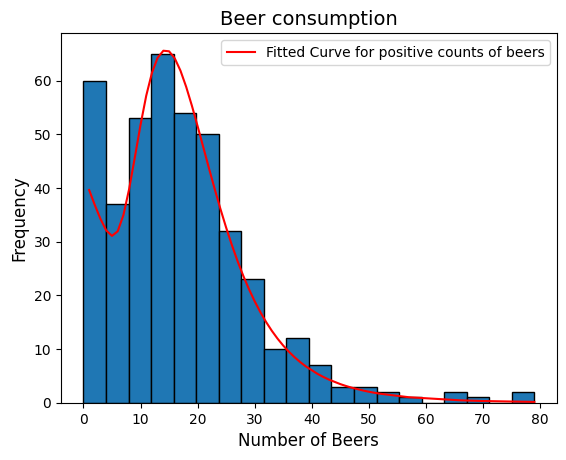

In [125]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.optimize as opt

streg1 = pd.read_csv('stregliste1.csv', delimiter=',', header=0, dtype=float)
beers1 = streg1[streg1.columns[0:5]].sum(axis=1)

streg2 = pd.read_csv('stregliste2.csv', delimiter=',', header=0, dtype=float)
beers2 = streg2[streg2.columns[0:5]].sum(axis=1)

streg3 = pd.read_csv('stregliste3.csv', delimiter=',', header=0, dtype=float)
beers3 = streg3[streg3.columns[0:5]].sum(axis=1)

streg4 = pd.read_csv('stregliste4.csv', delimiter=',', header=0, dtype=float)
beers4 = streg4[streg4.columns[0:5]].sum(axis=1)

beers_tot = np.concatenate((beers1, beers2, beers3, beers4))

bins = round(np.sqrt(len(beers_tot)))

positive_beers = beers_tot[beers_tot > 0] #log(0) not defined

plt.hist(beers_tot, bins=bins, edgecolor='black')
plt.xlabel('Number of Beers', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Beer consumption', fontsize=14)


hist, bin_edges = np.histogram(positive_beers, bins=bins)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2


mu = np.mean(np.log(positive_beers))
sigma = np.std(np.log(positive_beers))
bin_width = bin_edges[1] - bin_edges[0]


def f(x, mu, sigma, lam, A):
    return len(positive_beers) *bin_width * (A*lam*np.exp(-lam*x) + (1-A)*1/(x*sigma*np.sqrt(2*np.pi)) * np.exp(-((np.log(x)-mu)**2 / (2*sigma**2))))

var, cov = opt.curve_fit(f, bin_centers, hist, p0=[mu, sigma, 1, 0.5]);

print(f"Fitted parameters: mu = {var[0]}, sigma = {var[1]}, lambda = {var[2]}, A = {var[3]}")

print("Log-normal median:", np.exp(var[0]))
print("Log-normal mode:", np.exp(var[0] - var[1]**2))

plt.plot(np.sort(positive_beers), f(np.sort(positive_beers), *var), color='red', label='Fitted Curve for positive counts of beers');
plt.legend();
plt.show();







I interpret from the data and fit that the most common number of beers consumed is around 15 beers. I also notice how a surprisingly big amount of people had less than 5 beers. The histogram shows all numbers of beers consumed, including 0, while the fit only fits on positive numbers, as log(0) is not defined. It seems like the function fits the data quite well, althogu it does not account for those drinking 0 beers. 